In [1]:
import pandas as pd

dados = pd.read_csv("../data/processed/acidentes_prf_2020_2025.csv")
fatais = dados[dados["teve_morte"] == True]
fatais.shape

(29147, 10)

In [2]:
por_dia = fatais["dia_semana"].value_counts()
por_dia

dia_semana
domingo          5845
sábado           5344
sexta-feira      4273
segunda-feira    3676
quinta-feira     3496
quarta-feira     3303
terça-feira      3210
Name: count, dtype: int64

In [3]:
por_hora = fatais["hora"].value_counts().sort_index()
por_hora

hora
0      899
1      811
2      804
3      919
4     1019
5     1317
6     1249
7     1066
8      837
9      776
10     819
11     907
12     901
13     936
14    1082
15    1195
16    1206
17    1463
18    2390
19    2555
20    1907
21    1584
22    1347
23    1158
Name: count, dtype: int64

In [4]:
cruzado = pd.crosstab(fatais["dia_semana"], fatais["hora"])
cruzado.shape

(7, 24)

In [5]:
cruzado.idxmax(axis=1)

dia_semana
domingo          19
quarta-feira     19
quinta-feira     19
segunda-feira    19
sexta-feira      19
sábado           19
terça-feira      18
dtype: int64

## Conclusões da Pergunta 1

- Analisamos os 29.147 acidentes com morte de 2020 a 2025.
- Domingo (5.845) e sábado (5.344) tiveram mais acidentes com morte. Terça a quinta ficaram entre 3.210 e 3.496.
- O horário com mais acidentes com morte foi às 19h (2.555), seguido de 18h e 20h. Há também um pico menor entre 5h e 6h.
- Em 6 dos 7 dias a hora mais frequente foi 19h. Na terça-feira foi 18h.
- Esses números contam acidentes e não consideram quantos veículos circulam em cada dia e horário. Por isso, mostram quando mais acontecem, e não quando é mais arriscado dirigir.

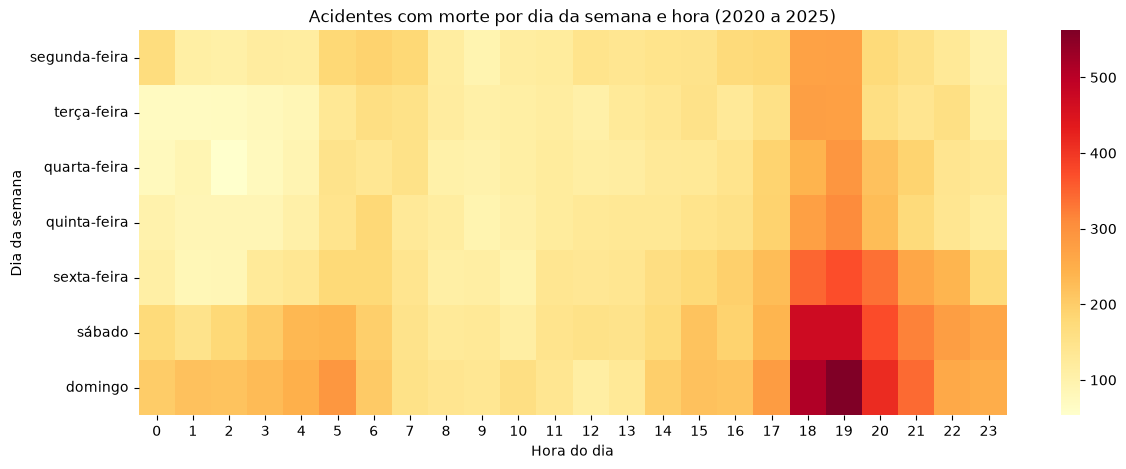

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

ordem = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira", "sábado", "domingo"]
cruzado = cruzado.loc[ordem]

plt.figure(figsize=(14, 5))
sns.heatmap(cruzado, cmap="YlOrRd")
plt.title("Acidentes com morte por dia da semana e hora (2020 a 2025)")
plt.xlabel("Hora do dia")
plt.ylabel("Dia da semana")
plt.show()

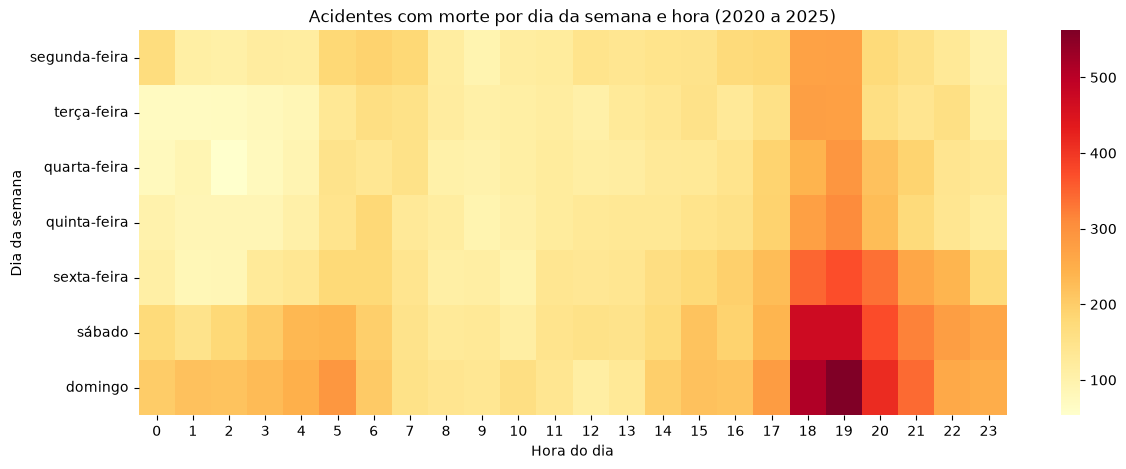

In [7]:
plt.figure(figsize=(14, 5))
sns.heatmap(cruzado, cmap="YlOrRd")
plt.title("Acidentes com morte por dia da semana e hora (2020 a 2025)")
plt.xlabel("Hora do dia")
plt.ylabel("Dia da semana")
plt.savefig("../dashboard/p1_mapa_calor_dia_hora.png", dpi=150, bbox_inches="tight")
plt.show()

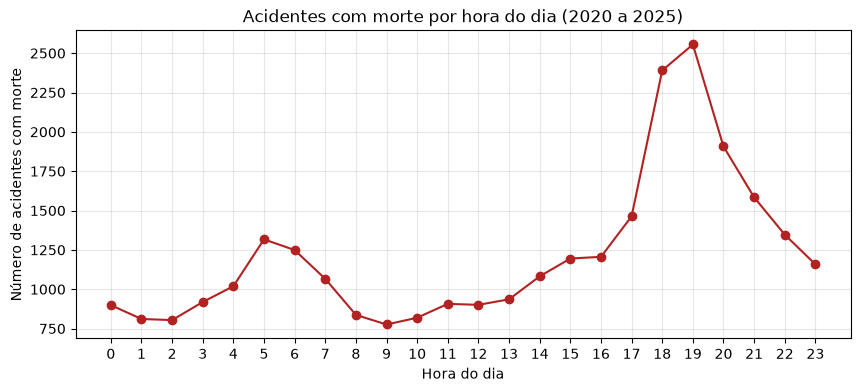

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(por_hora.index, por_hora.values, marker="o", color="firebrick")
plt.title("Acidentes com morte por hora do dia (2020 a 2025)")
plt.xlabel("Hora do dia")
plt.ylabel("Número de acidentes com morte")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.savefig("../dashboard/p1_linha_hora.png", dpi=150, bbox_inches="tight")
plt.show()